In [4]:
import pandas as pd
import numpy as np
import joblib

y_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\y_test")
y_predicted = np.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Model_Predictions_Saved\y_predicted_lr.npy")
y_predicted_probs = np.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Model_Predictions_Saved\y_predicted_probs_lr.npy")

lr_model = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Saved_Models\lr_model")

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [9]:
# Classification Performance for Logistic Regression

print(classification_report(y_test, y_predicted))

              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1035
           1       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



Based on the predictions of the logistic regression model, the accuracy appears to be roughly about 74%.

- Precision for detecting churn => ~ 50% (not performing well in precisely detecting the positive class from negative class)
- Recall for detecting churn => ~ 80% (identified majority of the positive classes amongst the entire positive class)

In [13]:
# ROC_AUC Score 

auc = roc_auc_score(y_test, y_predicted_probs)
print(f"ROC-AUC Score : {auc :.4f}")

ROC-AUC Score : 0.8504


ROC_AUC Score (0.8504) being closer to 1.00 means that the logistic regression model can identify most positive class data points (churn = 1), but due to low precision, many negative class data points (no churn = 0) end up being falsly labelled as positive class.

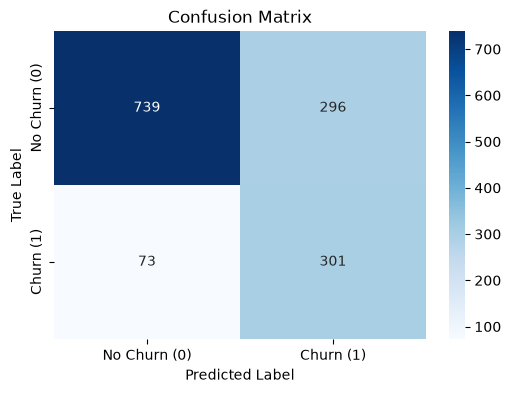

In [15]:
# Confusion Matrix 

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_predicted)

plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = "Blues", 
            xticklabels=['No Churn (0)', 'Churn (1)'], yticklabels=['No Churn (0)', 'Churn (1)'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

- By observing the confusion matrix, we can see that the model did a good job at detecting Churn (1) class, with only 73/374 being falsely labelled as No Churn (0). 
- But the model ended up classifying many No Churn (0) as Churn (1), with 296/1035 number of samples being falsely labelled as Churn (1).

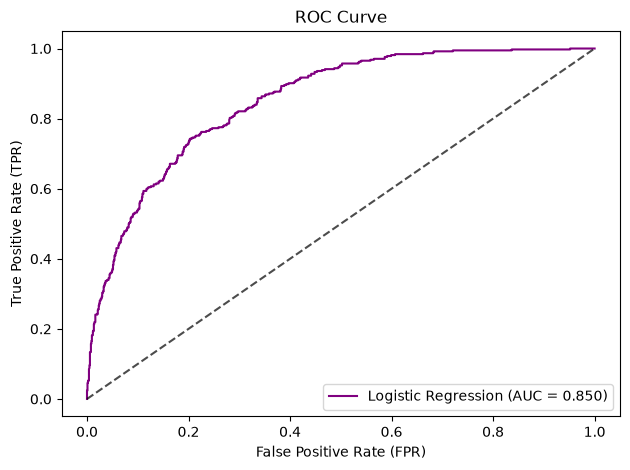

In [20]:
# ROC Curve 
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_test, y_predicted_probs)

plt.plot(fpr, tpr, color = 'purple', label = f"Logistic Regression (AUC = {auc :.3f})")
plt.plot([0,1], [0,1], 'k--', alpha = 0.7)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc = 'lower right')

plt.tight_layout()
plt.show()

As it appears from the ROC Curve, the model is detecting most positive class data points (Churn), but also false labelling the negative class (No Churn) as positive class. Better performance can be expected with different ML models.

In [23]:
# Feature Importance

x_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_test")

feat_imp_df = pd.DataFrame({
    'Feature' : x_test.columns,
    'Coefficient' : lr_model.coef_[0],
    'Odds_Ratio' : np.exp(lr_model.coef_[0])
}).sort_values(by = 'Coefficient', ascending = False)

print("__ Top Churn Drivers (Highest Impact that causes Churn) __")
display(feat_imp_df.head())

print("__ Top Retention Drivers (Highest Impact that lowers Churn) __")
display(feat_imp_df.tail())

__ Top Churn Drivers (Highest Impact that causes Churn) __


,Feature,Coefficient,Odds_Ratio
15,InternetService_Fiber optic,1.017859,2.767264
30,IsMonth_to_Month,0.610317,1.841015
20,PaymentMethod_Electronic check,0.435650,1.545968
13,PaperlessBilling,0.346678,1.414361
6,MultipleLines,0.258280,1.294701


__ Top Retention Drivers (Highest Impact that lowers Churn) __


,Feature,Coefficient,Odds_Ratio
5,PhoneService,-0.417230,0.658870
26,ChargeInflationRatio,-0.472698,0.623318
22,TotalCharges_log,-0.888514,0.411266
18,Contract_Two year,-1.017686,0.361430
16,InternetService_No,-1.256401,0.284677


The features with Odds_Ratio > 1.0, need to be addressed and optimized so as to reduce Churn risk.
- Many customers who have Internet Service seems to be Churning a lot. Need more investigation and take action on why they are churning.
- Month-to-Month based Customers are more likely to Churn compared to those with one year or two year contracts taken. Need to promote contract based plans rather monthly plans.
- Payment method needs to be optimized along with the Paperless Billing. Some changes in this area can affect how customers evaluate their budget and decide whether to churn or not.

The features with Odds_Ratio < 1.0, need to be maintained and optimize to maintain customers.
- Those with 2 year contract appear to be churning less compared to other plans. Should promote more of yearly based plans.
- Those customers without internet service (only landline customers) appear to be loyal. Those with Internet service already have dissatisfaction causing to churn. So landline users are sticking to the plan.
- Higher Total Charges, means the customers stays. This explains that customers after a certain limit of charges, will continue to use the plan without churning. 
- Phone service appears to be the main competing factor, so keeping good quality for phone service will maintain customers.

